<h1><b>Animal Conservation Data</b></h1>

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("Animal Dataset.csv")
df.index = df.index + 1
df.head()

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Habitat,Predators,Average Speed (km/h),Countries Found,Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth
1,Aardvark,105-130,40-65,Grey,20-30,Insectivore,"Savannas, Grasslands","Lions, Hyenas",40,Africa,Least Concern,Orycteropodidae,210-240,40,Solitary,1
2,Aardwolf,40-50,8-14,Yellow-brown,10-12,Insectivore,"Grasslands, Savannas","Lions, Leopards",24-30,Eastern and Southern Africa,Least Concern,Hyaenidae,90,40,Solitary,2-5
3,African Elephant,270-310,2700-6000,Grey,60-70,Herbivore,"Savannah, Forest","Lions, Hyenas",25,Africa,Vulnerable,Elephantidae,640-660,40,Herd-based,1
4,African Lion,80-110,120-250,Tan,10-14,Carnivore,"Grasslands, Savannas","Hyenas, Crocodiles",58,Africa,Vulnerable,Felidae,98-105,80,Group-based,2-4 (usually)
5,African Wild Dog,75-80,18-36,Multicolored,10-12,Carnivore,Savannahs,"Lions, Hyenas",56,Sub-Saharan Africa,Endangered,Canidae,70,56,Group-based,10-12


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 1 to 205
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Animal                   205 non-null    object
 1   Height (cm)              205 non-null    object
 2   Weight (kg)              205 non-null    object
 3   Color                    205 non-null    object
 4   Lifespan (years)         205 non-null    object
 5   Diet                     205 non-null    object
 6   Habitat                  205 non-null    object
 7   Predators                205 non-null    object
 8   Average Speed (km/h)     205 non-null    object
 9   Countries Found          205 non-null    object
 10  Conservation Status      205 non-null    object
 11  Family                   205 non-null    object
 12  Gestation Period (days)  205 non-null    object
 13  Top Speed (km/h)         205 non-null    object
 14  Social Structure         205 non-null    o

<h2>Dataset Exploration</h2>

In [4]:
df.shape

(205, 16)

In [5]:
df.describe

<bound method NDFrame.describe of                   Animal Height (cm) Weight (kg)             Color  \
1               Aardvark     105-130       40-65              Grey   
2               Aardwolf       40-50        8-14      Yellow-brown   
3       African Elephant     270-310   2700-6000              Grey   
4           African Lion      80-110     120-250               Tan   
5       African Wild Dog       75-80       18-36      Multicolored   
..                   ...         ...         ...               ...   
201                  Yak     140-160    500-1200      Brown, Black   
202  Yellow-Eyed Penguin       60-65         1-3     Yellow, White   
203            Yeti Crab    Up to 15   Up to 0.5      White, Hairy   
204                Zebra     220-340     400-900      Black, White   
205          Zebra Shark   Up to 330    Up to 32  Brown, Yellowish   

    Lifespan (years)         Diet               Habitat  \
1              20-30  Insectivore  Savannas, Grasslands   
2      

In [6]:
df['Diet'].value_counts()

Diet
Carnivore                 72
Herbivore                 54
Omnivore                  40
Insectivore               17
Carnivore, Scavenger       4
Carnivore, Insectivore     4
Carnivore, Piscivore       3
Omnivore, Insectivore      2
Filter Feeder              2
Herbivore, Omnivore        1
Piscivore                  1
Insectivore, Herbivore     1
Scavenger                  1
Nectar, Insects            1
Omnivore, Herbivore        1
Herbivore, Insectivore     1
Name: count, dtype: int64

In [7]:
df[['Animal','Average Speed (km/h)']]

,Animal,Average Speed (km/h)
1,Aardvark,40
2,Aardwolf,24-30
3,African Elephant,25
4,African Lion,58
5,African Wild Dog,56
...,...,...
201,Yak,24
202,Yellow-Eyed Penguin,25
203,Yeti Crab,Not Applicable
204,Zebra,25


In [8]:
df['Conservation Status'].unique()

array(['Least Concern', 'Vulnerable', 'Endangered', 'Not Evaluated',
       'Near Threatened', 'Not Applicable', 'Critically Endangered',
       'Varies', 'Data Deficient', 'Extinct',
       'Extinct (around 58 million years ago)',
       'Extinct (around 4,000 years ago)'], dtype=object)

In [9]:
df[['Animal','Conservation Status','Habitat']]

,Animal,Conservation Status,Habitat
1,Aardvark,Least Concern,"Savannas, Grasslands"
2,Aardwolf,Least Concern,"Grasslands, Savannas"
3,African Elephant,Vulnerable,"Savannah, Forest"
4,African Lion,Vulnerable,"Grasslands, Savannas"
5,African Wild Dog,Endangered,Savannahs
...,...,...,...
201,Yak,Least Concern,Mountains
202,Yellow-Eyed Penguin,Endangered,Coastal Areas
203,Yeti Crab,Not Evaluated,Hydrothermal Vents
204,Zebra,Least Concern,Grasslands


In [10]:
df[df['Conservation Status'] == 'Endangered'].count()

Animal                     33
Height (cm)                33
Weight (kg)                33
Color                      33
Lifespan (years)           33
Diet                       33
Habitat                    33
Predators                  33
Average Speed (km/h)       33
Countries Found            33
Conservation Status        33
Family                     33
Gestation Period (days)    33
Top Speed (km/h)           33
Social Structure           33
Offspring per Birth        33
dtype: int64

In [11]:
df['Social Structure'].unique()

array(['Solitary', 'Herd-based', 'Group-based', 'Colony-based', 'Flocks',
       'Social groups', 'Social pods', 'Pack-based', 'Varies', 'Eusocial'],
      dtype=object)

In [12]:
print(df[df.duplicated(subset='Animal', keep=False)])
df = df.drop_duplicates(subset='Animal')

                   Animal     Height (cm)     Weight (kg)              Color  \
29               Blobfish        Up to 30        Up to 10       Pinkish-gray   
30               Blobfish  Not Applicable  Not Applicable       Pinkish-gray   
78           Goblin Shark       Up to 320       Up to 210       Pinkish-gray   
79           Goblin Shark       Up to 366       Up to 210       Pinkish-gray   
82      Great White Shark       Up to 610      Up to 2268               Grey   
83      Great White Shark       Up to 670      Up to 2268        Gray, White   
85       Green Sea Turtle       Up to 120       Up to 200     Greenish-brown   
86       Green Sea Turtle          70-120          68-190              Green   
88                Hagfish       Up to 127       Up to 0.7         Pink, Gray   
89                Hagfish       Up to 127       Up to 0.6       Pinkish-gray   
107                 Lemur           30-50         0.6-3.5            Various   
108                 Lemur           30-6

In [13]:
df['Conservation Status'].value_counts()

Conservation Status
Least Concern                            67
Vulnerable                               34
Endangered                               31
Critically Endangered                    18
Not Evaluated                            15
Near Threatened                          14
Not Applicable                            9
Varies                                    3
Data Deficient                            2
Extinct                                   1
Extinct (around 58 million years ago)     1
Extinct (around 4,000 years ago)          1
Name: count, dtype: int64

In [14]:
df['Habitat'].value_counts()

Habitat
Rainforests            30
Forests, Grasslands     9
Grasslands              9
Grasslands, Forests     9
Forests                 8
                       ..
Forests, Caves          1
Sahara Desert           1
Gardens, Grasslands     1
Antarctic               1
Hydrothermal Vents      1
Name: count, Length: 97, dtype: int64

In [ ]:
#df[((df['Conservation Status']== 'Critically Endangered') | (df['Conservation Status']== 'Vulnerable') |(df['Conservation Status']== 'Endangered') | (df['Conservation Status']== 'Near Threatened'))&(df['Diet']=='Carnivore')]

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Habitat,Predators,Average Speed (km/h),Countries Found,Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth
4,African Lion,80-110,120-250,Tan,10-14,Carnivore,"Grasslands, Savannas","Hyenas, Crocodiles",58,Africa,Vulnerable,Felidae,98-105,80,Group-based,2-4 (usually)
5,African Wild Dog,75-80,18-36,Multicolored,10-12,Carnivore,Savannahs,"Lions, Hyenas",56,Sub-Saharan Africa,Endangered,Canidae,70,56,Group-based,10-12
18,Axolotl,Up to 30,Up to 300,Various,10-15,Carnivore,"Lakes, Canals","Fish, Birds",0.8,Mexico,Critically Endangered,Ambystomatidae,14-21,0.2-0.3,Solitary,100-300
24,Basking Shark,Up to 1100,400-700,"Gray, Brown",20-25,Carnivore,Oceans,"Orcas, Great White Sharks",14-28,Worldwide,Vulnerable,Cetorhinidae,36-42 months,14-28,Solitary,2-4
27,Bengal Tiger,90-110,220-260,"Orange, Black",10-15,Carnivore,"Grasslands, Mangroves","Humans, Crocodiles",65,"India, Bangladesh, Nepal",Endangered,Felidae,104-106,65,Solitary,2-4 (usually)
29,Blobfish,Up to 30,Up to 10,Pinkish-gray,Up to 100,Carnivore,Deep-sea,Not Applicable,Not Applicable,"Australia, New Zealand, Tasmania",Vulnerable,Psychrolutidae,Not Applicable,Not Applicable,Solitary,Not Applicable
35,Blue-Ringed Octopus,Up to 20,Up to 0.3,"Blue, Brown",6-8 months,Carnivore,"Coral Reefs, Tide Pools",Larger Fish,Not Applicable,Indo-Pacific region,Near Threatened,Octopodidae,50-70,Not Applicable,Solitary,Up to 100
44,Cheetah,70-90,20-72,Tan with Black Spots,10-12,Carnivore,"Grasslands, Savannas","Lions, Hyenas",112,"Africa, Iran, India",Vulnerable,Felidae,90-98,112,Solitary,3-5
46,Chinese Giant Salamander,Up to 180,Up to 65,Dark Brown,Up to 70,Carnivore,Freshwater,"Fish, Crustaceans",Not Applicable,China,Critically Endangered,Cryptobranchidae,50-60,Not Applicable,Solitary,Not Applicable
53,Dhole,50-55,12-21,"Red, Brown",10-15,Carnivore,"Forests, Grasslands","Tigers, Leopards",56,Asia,Endangered,Canidae,60-63,56,Pack-based,4-8


In [ ]:
#df[((df['Conservation Status']== 'Critically Endangered') | (df['Conservation Status']== 'Vulnerable') |(df['Conservation Status']== 'Endangered') | (df['Conservation Status']== 'Near Threatened'))&(df['Diet']=='Herbivore')]

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Habitat,Predators,Average Speed (km/h),Countries Found,Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth
3,African Elephant,270-310,2700-6000,Grey,60-70,Herbivore,"Savannah, Forest","Lions, Hyenas",25,Africa,Vulnerable,Elephantidae,640-660,40,Herd-based,1
8,American Bison,152-186,"318-1,000",Brown,15-20,Herbivore,"Grasslands, Plains","Wolves, Grizzly Bears",40-56,North America,Near Threatened,Bovidae,270-290,56,Group-based,1
11,Arabian Oryx,70-90,65-90,White,10-20,Herbivore,Desert,"Lions, Leopards",55,Middle East,Vulnerable,Bovidae,210-240,55,Herd-based,1
14,Asian Elephant,200-300,2000-5000,Grey,60-80,Herbivore,"Grasslands, Forests","Tigers, Leopards",40,Asia (Southeast),Endangered,Elephantidae,640-660,40,Herd-based,1
20,Baird's Tapir,76-107,150-400,"Brown, Black",25-30,Herbivore,"Rainforests, Grasslands","Jaguars, Crocodiles",48,Central and South America,Endangered,Tapiridae,390-395,48,Solitary,1
28,Black Rhinoceros,132-180,"800-1,400","Gray, Black",35-50,Herbivore,"Grasslands, Forests","Lions, Hyenas",56,Eastern and Southern Africa,Critically Endangered,Rhinocerotidae,450-480,56,Solitary,1
51,Coquerel's Sifaka,40-50,3-6,"White, Black",15-18,Herbivore,"Rainforests, Madagascar","Fossa, Hawks",30-45,Madagascar,Endangered,Indriidae,140-160,30,Group-based,1
55,Dugong,Up to 300,Up to 420,Gray,70-80,Herbivore,"Coastal Waters, Seagrass","Sharks, Orcas",10-15,"Indian Ocean, Western Pacific",Vulnerable,Dugongidae,13-14 months,27,Solitary,1
56,Eastern Gorilla,140-188,73-204,Black,40-50,Herbivore,Rainforests,"Leopards, Humans",40,Democratic Republic of Congo,Endangered,Hominidae,255-270,40,Social groups,1
69,Galápagos Tortoise,Up to 183,Up to 417,"Brown, Grey",100-150,Herbivore,Galápagos Islands,"Humans, Rats",0.3-0.5,Galápagos Islands,Vulnerable,Testudinidae,135,0.3,Solitary,Up to 16


<h2>Dataset Cleaning</h2>

In [17]:
upto_columns= ['Height (cm)','Weight (kg)','Lifespan (years)','Offspring per Birth']

In [18]:
for x in upto_columns:
    regex='Up.*'
    df[x][df[x].str.match(regex)]=df[x][df[x].str.match(regex)].str.split(' ',expand=True)[2]

In [19]:
for x in ['Height (cm)', 'Weight (kg)', 'Lifespan (years)', 'Offspring per Birth', 'Average Speed (km/h)','Top Speed (km/h)', 'Gestation Period (days)']:
    ab=df[x][df[x].str.contains('-')]
    df[x][df[x].str.contains('-')]=ab.str.split('-').str.get(-1)
    

In [20]:
df['Offspring per Birth'][df['Offspring per Birth'].str.endswith('(usually)')]=3

In [21]:
for x in ['Countries Found', 'Habitat', 'Predators']:
    split_columns = df[x].str.split(', ', expand=True)
    split_columns.columns = [f'{x} {i+1}' for i in range(split_columns.shape[1])]

    df = pd.concat([df, split_columns], axis=1)
    df.drop(columns=[x], inplace=True )
    

In [22]:
df

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Average Speed (km/h),Conservation Status,Family,Gestation Period (days),...,Offspring per Birth,Countries Found 1,Countries Found 2,Countries Found 3,Countries Found 4,Habitat 1,Habitat 2,Habitat 3,Predators 1,Predators 2
1,Aardvark,130,65,Grey,30,Insectivore,40,Least Concern,Orycteropodidae,240,...,1,Africa,None,None,None,Savannas,Grasslands,None,Lions,Hyenas
2,Aardwolf,50,14,Yellow-brown,12,Insectivore,30,Least Concern,Hyaenidae,90,...,5,Eastern and Southern Africa,None,None,None,Grasslands,Savannas,None,Lions,Leopards
3,African Elephant,310,6000,Grey,70,Herbivore,25,Vulnerable,Elephantidae,660,...,1,Africa,None,None,None,Savannah,Forest,None,Lions,Hyenas
4,African Lion,110,250,Tan,14,Carnivore,58,Vulnerable,Felidae,105,...,3,Africa,None,None,None,Grasslands,Savannas,None,Hyenas,Crocodiles
5,African Wild Dog,80,36,Multicolored,12,Carnivore,56,Endangered,Canidae,70,...,12,Sub-Saharan Africa,None,None,None,Savannahs,None,None,Lions,Hyenas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,Yak,160,1200,"Brown, Black",25,Herbivore,24,Least Concern,Bovidae,280,...,50,Himalayas,Central Asia,None,None,Mountains,None,None,Snow Leopards,Wolves
202,Yellow-Eyed Penguin,65,3,"Yellow, White",20,Carnivore,25,Endangered,Spheniscidae,90,...,1,New Zealand,None,None,None,Coastal Areas,None,None,Seals,Orcas
203,Yeti Crab,15,0.5,"White, Hairy",20,Omnivore,Not Applicable,Not Evaluated,Kiwaidae,Not Applicable,...,Not Applicable,Pacific Ocean,None,None,None,Hydrothermal Vents,None,None,Not Applicable,None
204,Zebra,340,900,"Black, White",25,Herbivore,25,Least Concern,Equidae,365,...,20,Africa,None,None,None,Grasslands,None,None,Lions,Hyenas


In [23]:
#df['Countries Found 4'].replace('None',np.nan,inplace=True)
#df['Countries Found 3'].replace('None',np.nan,inplace=True)
#df['Countries Found 2'].replace('None',np.nan,inplace=True)

In [24]:
df['Countries Found 1'].value_counts()

Countries Found 1
Worldwide                     15
Australia                     12
Africa                        10
North America                 10
Central and South America     10
                              ..
Indian subcontinent            1
Southwestern United States     1
Brazil                         1
Western Colombia               1
Himalayas                      1
Name: count, Length: 72, dtype: int64

In [25]:
df['Countries Found 2'].value_counts()

Countries Found 2
South Asia            5
Asia                  4
North Africa          3
Europe                3
Africa                3
Nepal                 2
Australia             2
Malaysia              2
China                 2
Mexico                2
North America         2
New Zealand           2
Uganda                1
Tibet                 1
Subarctic             1
Russia                1
Alaska                1
Laos                  1
Southeast Asia        1
Chile                 1
Indonesia             1
Philippines           1
Gulf of Mexico        1
Central               1
Portugal              1
Atlantic Ocean        1
Southeastern Bahia    1
Horn of Africa        1
New Guinea            1
Western Pacific       1
Pacific Oceans        1
Iran                  1
Bangladesh            1
Arctic                1
Central Asia          1
Name: count, dtype: int64

In [26]:
df['Countries Found 3'].value_counts()

Countries Found 3
Asia                 3
Middle East          2
Bhutan               2
Americas             2
Nepal                1
Tasmania             1
Indonesia            1
India                1
Southeast Asia       1
North Korea          1
and South America    1
Australia            1
North Africa         1
Name: count, dtype: int64

In [27]:
df['Countries Found 4'].value_counts()

Countries Found 4
Oceania    1
India      1
Name: count, dtype: int64

In [28]:
df.drop(columns=['Countries Found 2','Countries Found 3','Countries Found 4'], inplace=True)

In [29]:
df = df.rename(columns={'Countries Found 1': 'Countries Found'})

In [30]:
df['Habitat 1'].replace('None',np.nan,inplace=True)
df['Habitat 2'].replace('None',np.nan,inplace=True)
df['Predators 1'].replace('None',np.nan,inplace=True)
df['Predators 2'].replace('None',np.nan,inplace=True)

In [31]:
print(df['Habitat 1'].isna().sum(),df['Habitat 2'].isna().sum(),df['Habitat 3'].isna().sum())

0 112 195


In [32]:
print(df['Predators 1'].isna().sum(),df['Predators 2'].isna().sum())

0 33


In [33]:
df['Habitat 2'] = df['Habitat 2'].fillna(df['Habitat 1'])

In [34]:
df.drop(columns=['Habitat 3'], inplace=True)

In [35]:
df['Predators 2'] = df['Predators 2'].fillna(df['Predators 1'])

In [36]:
df.columns

Index(['Animal', 'Height (cm)', 'Weight (kg)', 'Color', 'Lifespan (years)',
       'Diet', 'Average Speed (km/h)', 'Conservation Status', 'Family',
       'Gestation Period (days)', 'Top Speed (km/h)', 'Social Structure',
       'Offspring per Birth', 'Countries Found', 'Habitat 1', 'Habitat 2',
       'Predators 1', 'Predators 2'],
      dtype='object')

In [37]:
df.shape

(196, 18)

In [38]:
df.isna().sum()


Animal                     0
Height (cm)                0
Weight (kg)                0
Color                      0
Lifespan (years)           0
Diet                       0
Average Speed (km/h)       0
Conservation Status        0
Family                     0
Gestation Period (days)    0
Top Speed (km/h)           0
Social Structure           0
Offspring per Birth        0
Countries Found            0
Habitat 1                  0
Habitat 2                  0
Predators 1                0
Predators 2                0
dtype: int64

In [39]:
df.loc[df['Height (cm)'] == '']


,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Average Speed (km/h),Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth,Countries Found,Habitat 1,Habitat 2,Predators 1,Predators 2


In [40]:
df.drop(df[df['Height (cm)'] == ''].index,inplace= True)

In [41]:
df.replace(',', '', regex=True,inplace=True)
df.replace('Varies',np.nan,inplace=True)

In [42]:
df.dropna(inplace=True)

In [43]:
df['Lifespan (years)']=df['Lifespan (years)'].str.replace(r'\+', '', regex=True)

In [44]:
df['Average Speed (km/h)'][df['Average Speed (km/h)'].str.contains(r'.*water.*', regex=True)]=df['Average Speed (km/h)'][df['Average Speed (km/h)'].str.contains(r'.*water.*', regex=True)].str.split(" ",expand=True)[0]

In [45]:
df.replace(r'\(in burrow\)','',regex=True,inplace=True)

In [46]:
df['Gestation Period (days)'][df['Gestation Period (days)'].str.contains(r'.*days.*', regex=True)]='10'

In [47]:
df['Gestation Period (days)'][df['Gestation Period (days)'].str.contains(r'.*weeks.*', regex=True)]

58     10 weeks
93      2 weeks
130     9 weeks
Name: Gestation Period (days), dtype: object

In [48]:
df['Gestation Period (days)'][df['Gestation Period (days)'].str.contains(r'.*weeks.*', regex=True)]=f'{9 * 7}'

In [49]:
df['Gestation Period (days)'][df['Gestation Period (days)'].str.contains(r'.*months.*', regex=True)]

24     42 months
33     12 months
38     12 months
55     14 months
82     18 months
104     8 months
122    16 months
184    11 months
Name: Gestation Period (days), dtype: object

In [50]:
df['Gestation Period (days)'] = df['Gestation Period (days)'].apply(
    lambda x: f'{int(x.split()[0]) * 30}' if 'months' in x else x
)

In [51]:
df['Offspring per Birth']=df['Offspring per Birth'].str.replace(r')',"")

In [52]:
df['Offspring per Birth']=df['Offspring per Birth'].str.replace(r'Hundreds',"100")

In [53]:
# Initialize an empty list to store the non-convertible values
non_convertible_values = []

# Iterate through the column and attempt to convert to float
for value in df['Offspring per Birth']:
    try:
        float(value)
    except ValueError:
        non_convertible_values.append(value)

# Create a DataFrame containing the non-convertible values
df.loc[df['Offspring per Birth'].isin(non_convertible_values), 'Offspring per Birth'] = df.loc[df['Offspring per Birth'].isin(non_convertible_values), 'Offspring per Birth'].str.split(" ",expand=True)[0]

In [54]:
df.columns

Index(['Animal', 'Height (cm)', 'Weight (kg)', 'Color', 'Lifespan (years)',
       'Diet', 'Average Speed (km/h)', 'Conservation Status', 'Family',
       'Gestation Period (days)', 'Top Speed (km/h)', 'Social Structure',
       'Offspring per Birth', 'Countries Found', 'Habitat 1', 'Habitat 2',
       'Predators 1', 'Predators 2'],
      dtype='object')

In [55]:
float_columns = ['Height (cm)','Weight (kg)','Lifespan (years)','Average Speed (km/h)','Gestation Period (days)','Top Speed (km/h)','Offspring per Birth']
for x in float_columns:    
    df[x] = df[x].str.replace('[a-zA-Z]', '', regex=True).str.strip()
    df[x] = df[x].replace('', pd.NA)
    df[x] = df[x].dropna()
    df[x] = df[x].astype(float)

In [56]:
df['Height-to-Weight Ratio'] = df['Height (cm)'] / df['Weight (kg)']
df['Height-to-Weight Ratio']

1       2.000000
2       3.571429
3       0.051667
4       0.440000
5       2.222222
         ...    
201     0.133333
202    21.666667
203    30.000000
204     0.377778
205    10.312500
Name: Height-to-Weight Ratio, Length: 188, dtype: float64

In [57]:
df[df['Conservation Status'] == 'Extinct']

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Average Speed (km/h),Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth,Countries Found,Habitat 1,Habitat 2,Predators 1,Predators 2,Height-to-Weight Ratio
170,Tasmanian Tiger,130.0,30.0,Yellow-brown,7.0,Carnivore,72.0,Extinct,Thylacinidae,128.0,72.0,Solitary,3.0,Australia,Australia,Australia,Humans,Dingoes,4.333333


In [58]:
df.loc[176, 'Conservation Status'] = 'Extinct'


In [59]:
df['Conservation Status'] = df['Conservation Status'].replace({'Not Applicable': 'Least Concern', 'Not Evaluated': 'Least Concern', 'Data Deficient': 'Least Concern', 'Vulnerable': 'Endangered', 'Critically Endangered': 'Endangered', 'Near Threatened':'Endangered', 'Extinct (around 58 million years ago)': 'Extinct'})

df.head(10)

,Animal,Height (cm),Weight (kg),Color,Lifespan (years),Diet,Average Speed (km/h),Conservation Status,Family,Gestation Period (days),Top Speed (km/h),Social Structure,Offspring per Birth,Countries Found,Habitat 1,Habitat 2,Predators 1,Predators 2,Height-to-Weight Ratio
1,Aardvark,130.0,65.0,Grey,30.0,Insectivore,40.0,Least Concern,Orycteropodidae,240.0,40.0,Solitary,1.0,Africa,Savannas,Grasslands,Lions,Hyenas,2.000000
2,Aardwolf,50.0,14.0,Yellow-brown,12.0,Insectivore,30.0,Least Concern,Hyaenidae,90.0,40.0,Solitary,5.0,Eastern and Southern Africa,Grasslands,Savannas,Lions,Leopards,3.571429
3,African Elephant,310.0,6000.0,Grey,70.0,Herbivore,25.0,Endangered,Elephantidae,660.0,40.0,Herd-based,1.0,Africa,Savannah,Forest,Lions,Hyenas,0.051667
4,African Lion,110.0,250.0,Tan,14.0,Carnivore,58.0,Endangered,Felidae,105.0,80.0,Group-based,NaN,Africa,Grasslands,Savannas,Hyenas,Crocodiles,0.440000
5,African Wild Dog,80.0,36.0,Multicolored,12.0,Carnivore,56.0,Endangered,Canidae,70.0,56.0,Group-based,12.0,Sub-Saharan Africa,Savannahs,Savannahs,Lions,Hyenas,2.222222
6,Alpine Ibex,101.0,120.0,Brown,20.0,Herbivore,64.0,Least Concern,Bovidae,150.0,64.0,Group-based,1.0,European Alps,Mountains,Alpine,Wolves,Golden Eagles,0.841667
7,Amazon Rainforest Frog,13.0,0.5,Various,17.0,Insectivore,1.0,Least Concern,Dendrobatidae,15.0,0.8,Solitary,40.0,Amazon Rainforest,Amazon Rainforest,Amazon Rainforest,Birds,Snakes,26.000000
8,American Bison,186.0,1000.0,Brown,20.0,Herbivore,56.0,Endangered,Bovidae,290.0,56.0,Group-based,1.0,North America,Grasslands,Plains,Wolves,Grizzly Bears,0.186000
9,Anteater,91.0,41.0,Brown White,20.0,Insectivore,24.0,Least Concern,Myrmecophagidae,210.0,24.0,Solitary,1.0,Central and South America,Grasslands,Forests,Jaguars,Pumas,2.219512
10,Arabian Horse,160.0,1000.0,Various,30.0,Herbivore,65.0,Least Concern,Equidae,342.0,65.0,Herd-based,1.0,Middle East,Middle East,North Africa,Humans,Predators,0.160000


In [60]:
df['Diet'] = df['Diet'].replace({'Insectivore':'Carnivore', 'Carnivore Scavenger':'Carnivore', 'Filter Feeder':'Herbivore', 'Piscivore':'Carnivore', 'Omnivore Insectivore': 'Omnivore', 'Carnivore Scavenger': 'Scavenger', 'Insectivore Herbivore': 'Omnivore', 'Herbivore Omnivore': 'Omnivore', 'Carnivore Insectivore': 'Carnivore', 'Herbivore Insectivore': 'Omnivore', 'Carnivore Piscivore': 'Carnivore', 'Omnivore Herbivore': 'Omnivore', 'Nectar Insects': 'Herbivore'})

<h2>Exploratory Data Analysis</h2>

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 188 entries, 1 to 205
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Animal                   188 non-null    object 
 1   Height (cm)              188 non-null    float64
 2   Weight (kg)              188 non-null    float64
 3   Color                    188 non-null    object 
 4   Lifespan (years)         188 non-null    float64
 5   Diet                     188 non-null    object 
 6   Average Speed (km/h)     173 non-null    float64
 7   Conservation Status      188 non-null    object 
 8   Family                   188 non-null    object 
 9   Gestation Period (days)  179 non-null    float64
 10  Top Speed (km/h)         161 non-null    float64
 11  Social Structure         188 non-null    object 
 12  Offspring per Birth      170 non-null    float64
 13  Countries Found          188 non-null    object 
 14  Habitat 1                188 no

In [62]:
for attr in ['Height (cm)','Weight (kg)', 'Lifespan (years)', 'Offspring per Birth', 'Height-to-Weight Ratio', 'Average Speed (km/h)', 'Gestation Period (days)', 'Top Speed (km/h)']:
    print(df[attr].describe())
    print()
    print(attr ,round(df[attr].mean(),2))
    print()

count     188.000000
mean      186.370745
std       384.412257
min         5.000000
25%        45.750000
50%        83.000000
75%       160.000000
max      3200.000000
Name: Height (cm), dtype: float64

Height (cm) 186.37

count      188.000000
mean       870.450766
std       5033.623095
min          0.006000
25%          4.000000
50%         40.000000
75%        201.000000
max      57000.000000
Name: Weight (kg), dtype: float64

Weight (kg) 870.45

count    188.000000
mean      27.601064
std       28.929481
min        2.000000
25%       14.000000
50%       20.000000
75%       30.000000
max      300.000000
Name: Lifespan (years), dtype: float64

Lifespan (years) 27.6

count       170.000000
mean       1272.300000
std       15351.603047
min           1.000000
25%           1.000000
50%           2.000000
75%          10.750000
max      200000.000000
Name: Offspring per Birth, dtype: float64

Offspring per Birth 1272.3

count    188.000000
mean      25.083079
std       82.921470
min     

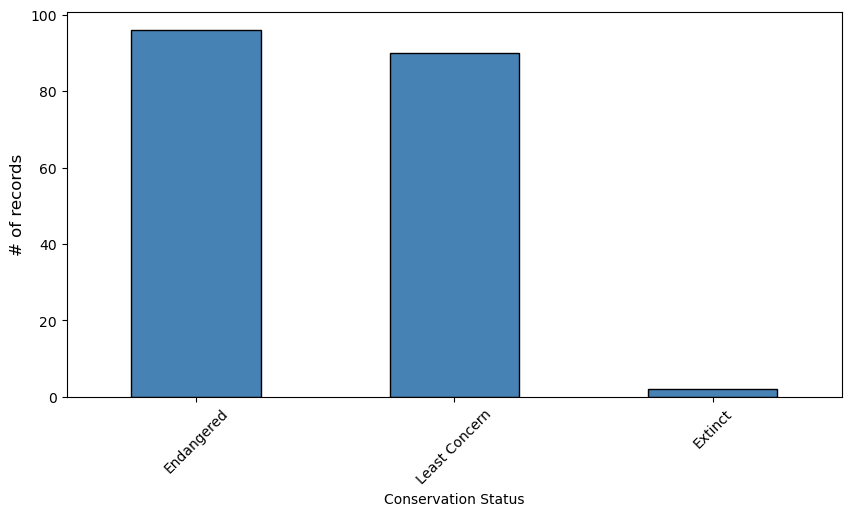

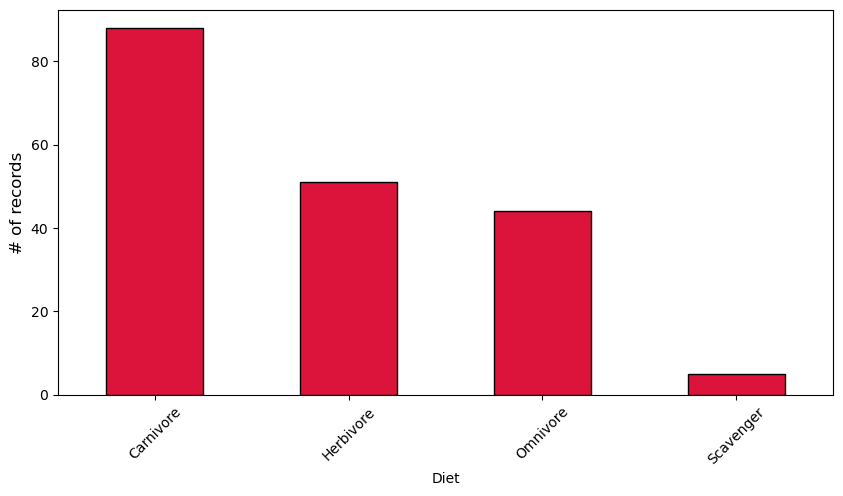

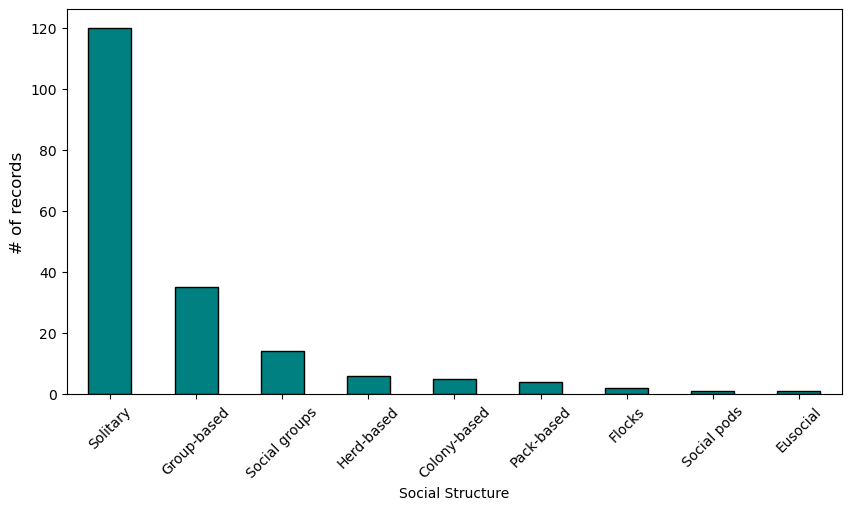

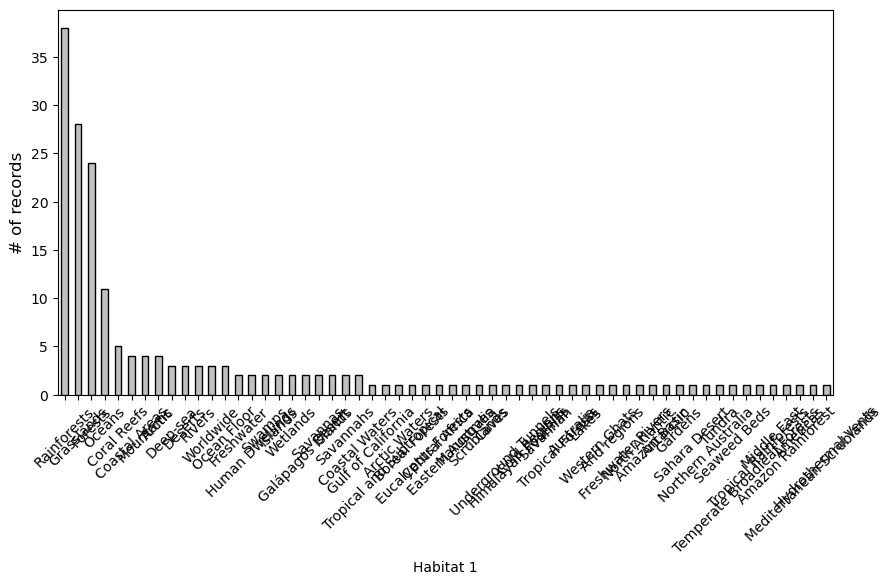

In [65]:
for i, attr in enumerate(['Conservation Status','Diet','Social Structure','Habitat 1']):
    col= ['steelblue', 'crimson', 'teal', 'silver']
    df[attr].value_counts().plot(kind='bar', figsize=(10,5), color=col[i], edgecolor='black')
    #i+=1
    plt.xticks(rotation=45)
    plt.ylabel("# of records", fontsize=12)
    plt.savefig(attr +' Bar Graph.png', dpi=300)
    plt.show()

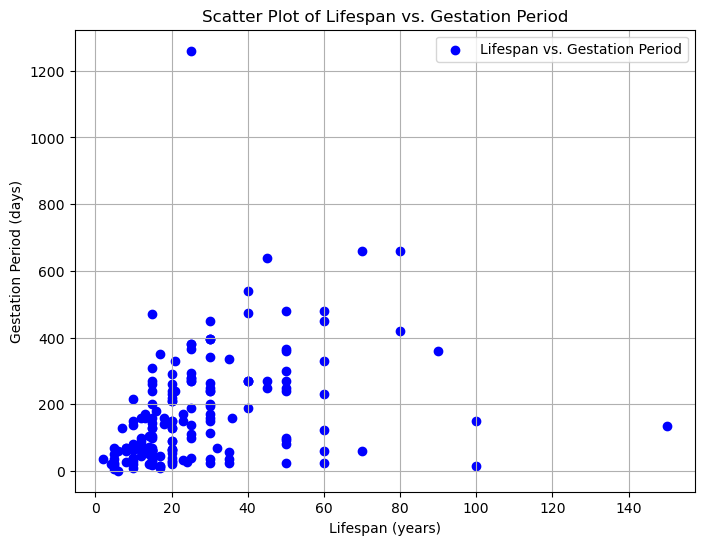

In [66]:
plt.figure(figsize=(8, 6))
plt.scatter(df['Lifespan (years)'], df['Gestation Period (days)'], c='blue', marker='o', label='Lifespan vs. Gestation Period')
plt.xlabel('Lifespan (years)')
plt.ylabel('Gestation Period (days)')
plt.title('Scatter Plot of Lifespan vs. Gestation Period')
plt.legend()
plt.grid(True)
plt.show()

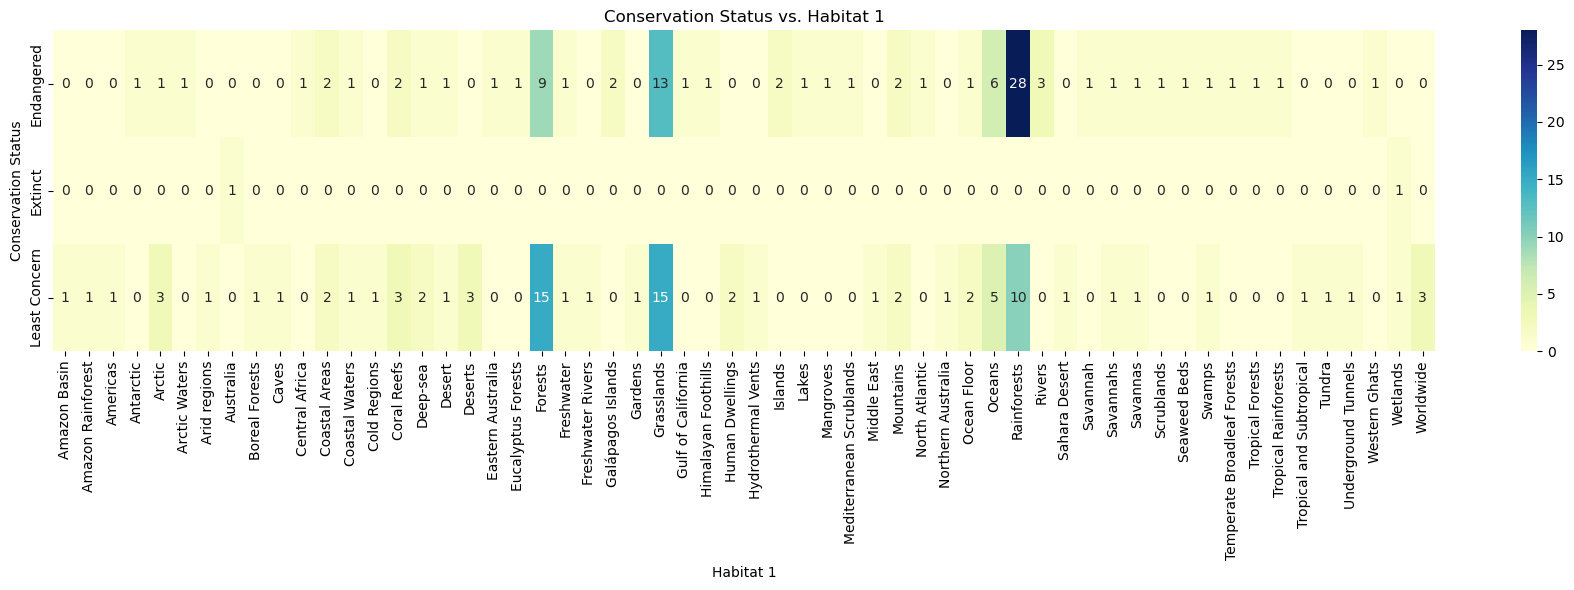

In [67]:
cvs_hab = pd.crosstab(df['Conservation Status'], df['Habitat 1'])

plt.figure(figsize=(18, 6))

sns.heatmap(cvs_hab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Habitat 1')
plt.savefig('Conservation Status vs. Habitat 1.png', dpi=300)

plt.tight_layout()

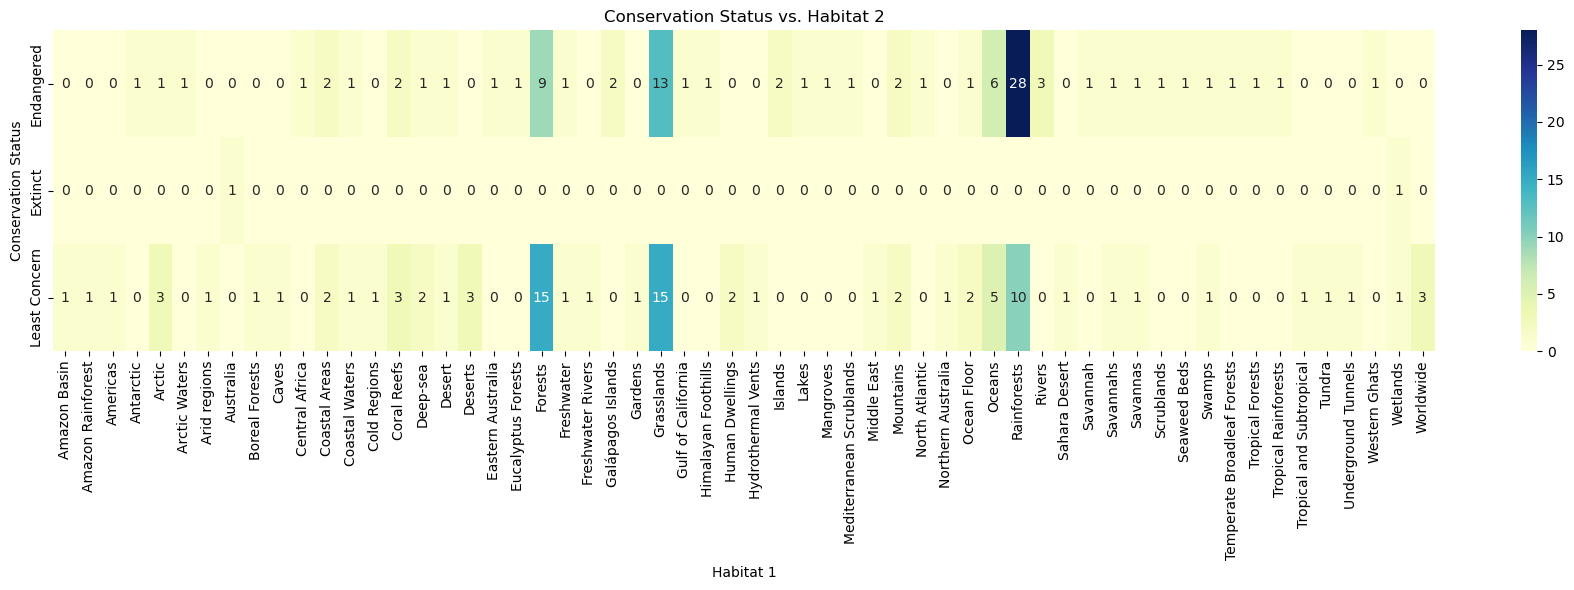

In [68]:
cvs_hab2 = pd.crosstab(df['Conservation Status'], df['Habitat 2'])

plt.figure(figsize=(18, 6))

sns.heatmap(cvs_hab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Habitat 2')

plt.tight_layout()

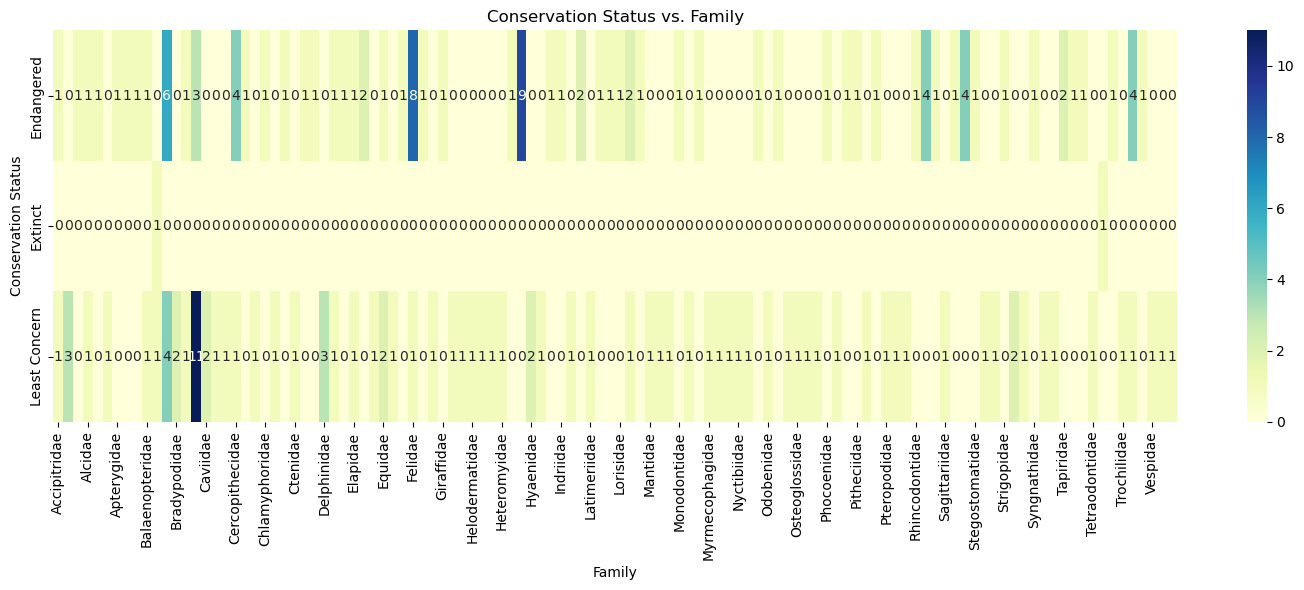

In [69]:
cvs_fam = pd.crosstab(df['Conservation Status'], df['Family'])
plt.figure(figsize=(28, 6))

plt.subplot(1, 2, 1)
sns.heatmap(cvs_fam, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Family')
plt.savefig('Conservation Status vs. Family.png', dpi=300)
plt.tight_layout()

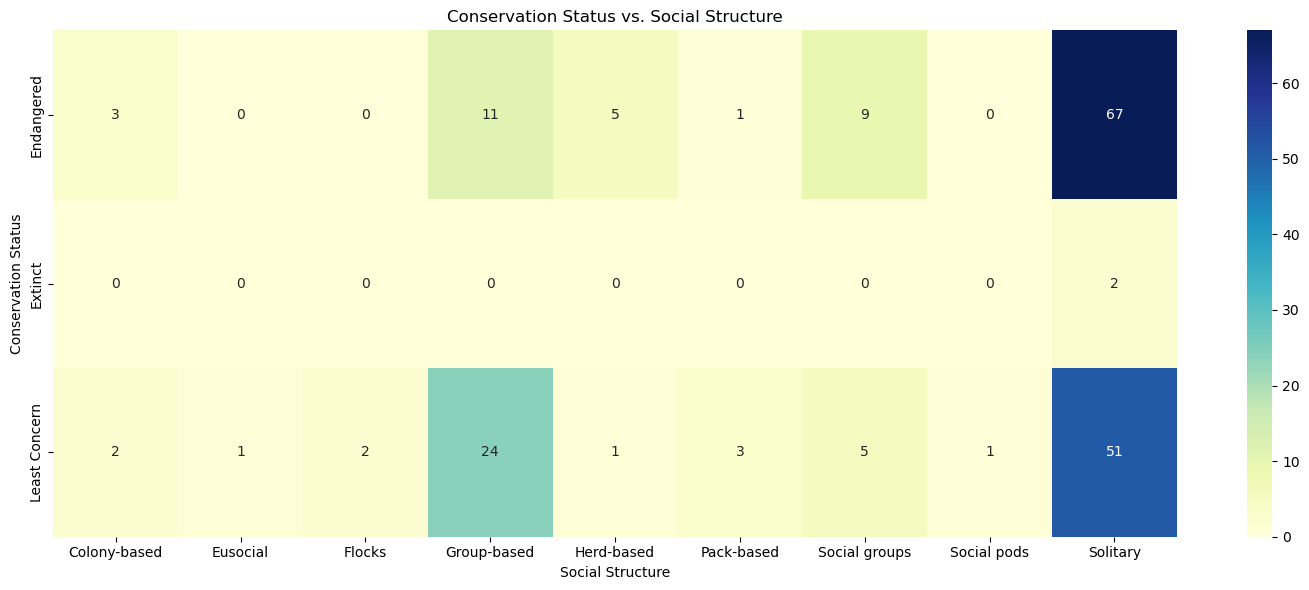

In [70]:
cvs_soc = pd.crosstab(df['Conservation Status'], df['Social Structure'])
plt.figure(figsize=(28, 6))

plt.subplot(1, 2, 1)
sns.heatmap(cvs_soc, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Social Structure')
plt.savefig('Conservation Status vs. Social Structure.png', dpi=300)
plt.tight_layout()

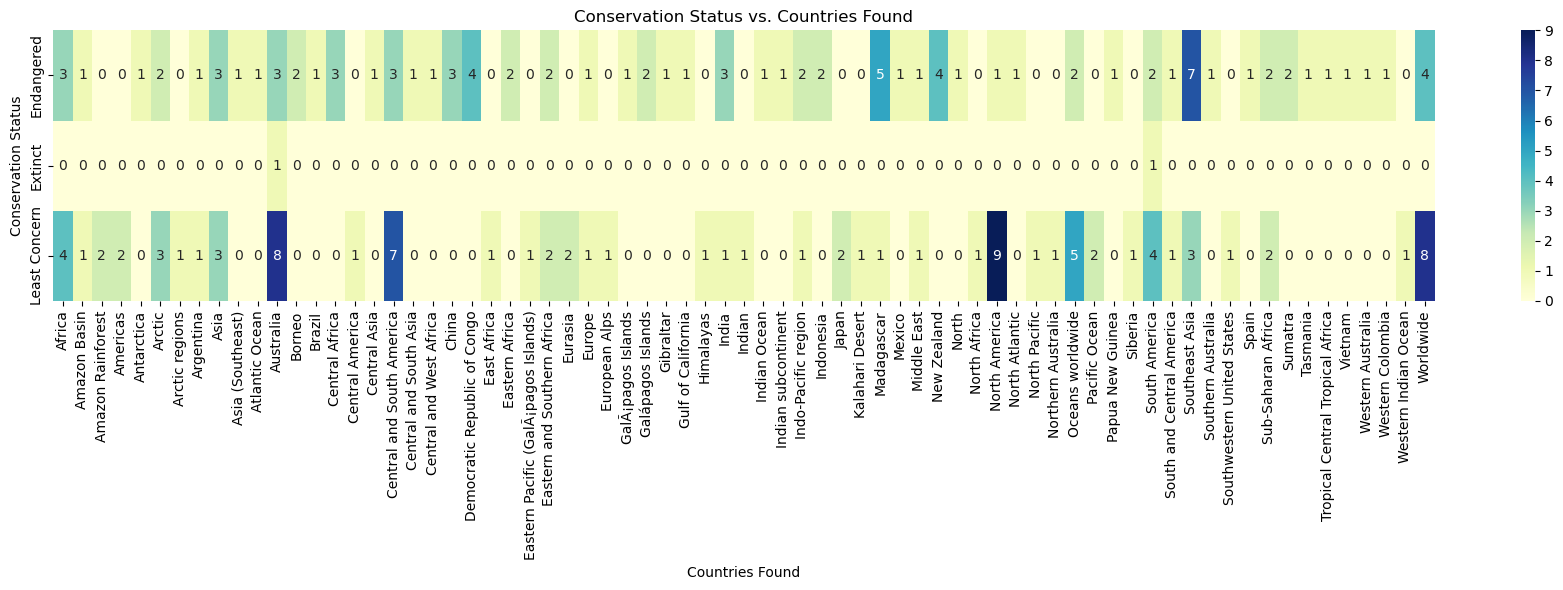

In [71]:
cvs_hab = pd.crosstab(df['Conservation Status'], df['Countries Found'])

plt.figure(figsize=(18, 6))

sns.heatmap(cvs_hab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Countries Found')

plt.tight_layout()

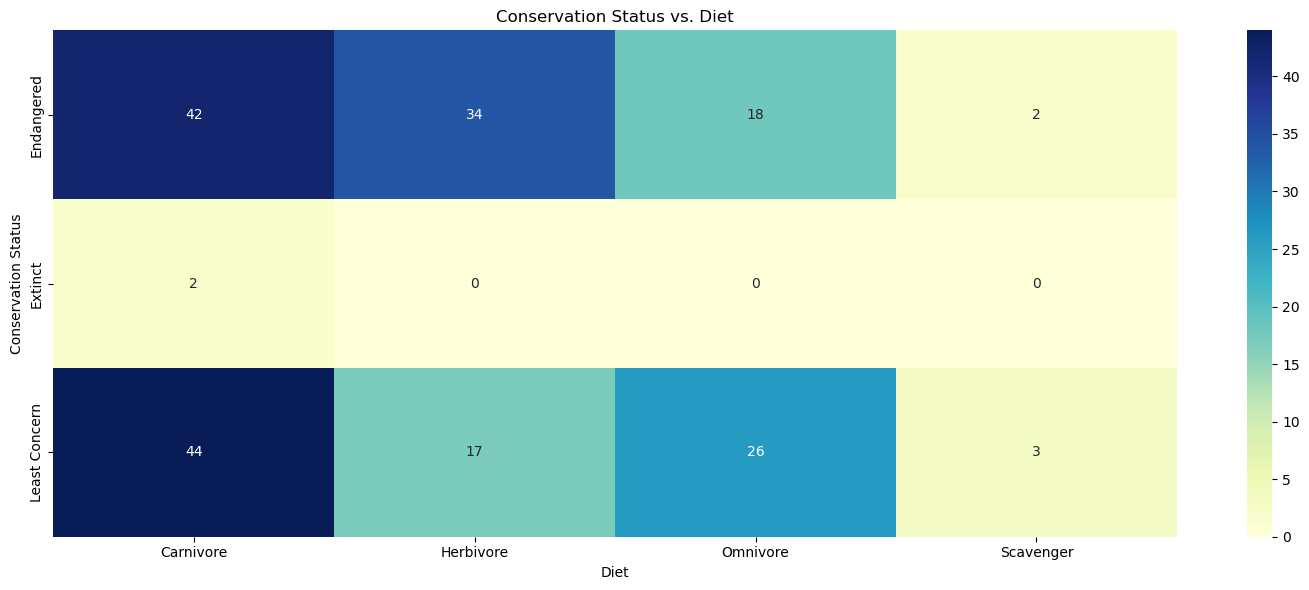

In [72]:
cvs_diet = pd.crosstab(df['Conservation Status'], df['Diet'])
plt.figure(figsize=(28, 6))

plt.subplot(1, 2, 1)
sns.heatmap(cvs_diet, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Conservation Status vs. Diet')
plt.savefig('Conservation Status vs. Diet.png', dpi=300)
plt.tight_layout()

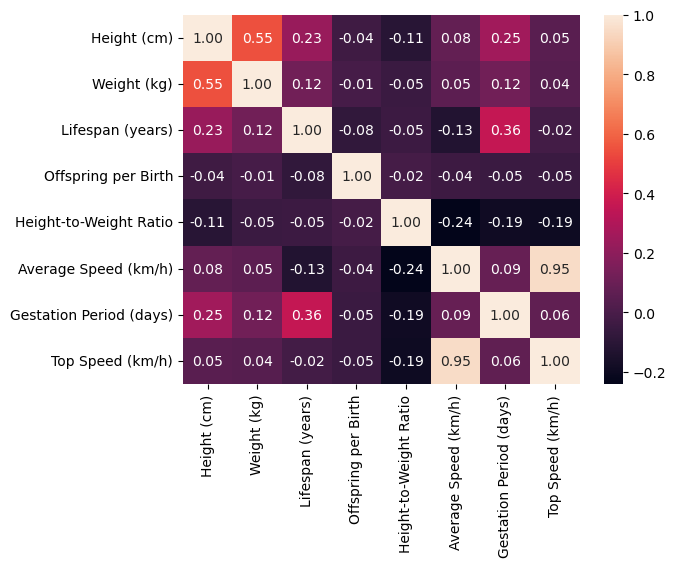

In [73]:
df2 = df[['Height (cm)','Weight (kg)', 'Lifespan (years)', 'Offspring per Birth', 'Height-to-Weight Ratio', 'Average Speed (km/h)', 'Gestation Period (days)', 'Top Speed (km/h)']]
corr = df2.corr(method='pearson')
sns.heatmap(corr, annot=True, fmt=".2f")
plt.savefig('Animal Info Heatmap.png', dpi=300)
plt.show()

## Conservation Status Classification

Train a random forest using diet, average speed, gestation period, social structure, countries found, lifespan, and both habitat fields. 

<p>
The Conservation Status Model was created utilizing a Random Forest Model. The model used several numerical and categorical columns for training, including Diet, Social Structure, Habitat 1 and Habitat 2, Countries Found, Gestation Period, Lifespan, and Average Speed. The model's target variable was Conservation Status, with three categories: Least Concern, Endangered, and Extinct. The model achieved 63% accuracy and a 63% F1-score in classifying the animal's conservation status. Notably, the model's most important features were lifespan, gestation period, average speed, habitat (Australia and wetlands), countries found (South America, Australia), and a solitary social structure. This supports some previous findings within the heatmaps on conservation status, habitats, and social structure in the exploratory data analysis section. Notably, the animals' diet played little role in determining conservation status compared with the other feature columns.
</p>

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_features = ['Average Speed (km/h)', 'Gestation Period (days)', 'Lifespan (years)']
categorical_features = ['Diet', 'Social Structure', 'Habitat 1', 'Habitat 2', 'Countries Found']
#separate numeric + categorical features 
target = 'Conservation Status' #establish target var
required_columns = numeric_features + categorical_features + [target]


missing_columns = sorted(set(required_columns) - set(df.columns))  # check for missing columns

if missing_columns:
    raise KeyError(f'Missing required columns: {missing_columns}')

model_data = df[required_columns].copy()

for column in numeric_features:
    model_data[column] = pd.to_numeric(model_data[column], errors='coerce') #double check data is numeric 

model_data = model_data.dropna(subset=[target]) #remove missing vaiables

X = model_data[numeric_features + categorical_features]  

y = model_data[target] 

class_counts = y.value_counts() 
print('Rows per conservation-status class:')
print(class_counts)
if class_counts.min() < 2:
    raise ValueError('Each class needs at least two rows for a stratified train/test split.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', SimpleImputer(strategy='median'), numeric_features),
        ('categorical', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical_features),
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=500,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1,
    )),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(f'\nBalanced accuracy: {balanced_accuracy_score(y_test, predictions):.3f}')
print('\nClassification report:')
print(classification_report(y_test, predictions, zero_division=0))

feature_names = model.named_steps['preprocessor'].get_feature_names_out() 
feature_importances = model.named_steps['classifier'].feature_importances_
importance = pd.Series(feature_importances, index=feature_names).sort_values(ascending=False)
print('Top feature importances:')
print(importance.head(25)) 

Rows per conservation-status class:
Conservation Status
Endangered       96
Least Concern    90
Extinct           2
Name: count, dtype: int64

Balanced accuracy: 0.636

Classification report:
               precision    recall  f1-score   support

   Endangered       0.69      0.55      0.61        20
Least Concern       0.59      0.72      0.65        18

     accuracy                           0.63        38
    macro avg       0.64      0.64      0.63        38
 weighted avg       0.64      0.63      0.63        38

Top feature importances:
numeric__Lifespan (years)                                 0.114464
numeric__Gestation Period (days)                          0.098772
numeric__Average Speed (km/h)                             0.092686
categorical__Habitat 2_Australia                          0.046394
categorical__Habitat 1_Australia                          0.045275
categorical__Habitat 2_Wetlands                           0.043404
categorical__Habitat 1_Wetlands                 

In [ ]:
#from sklearn.model_selection import cross_val_score
#accuracy = np.mean(cross_val_score(model, X, y, cv=10, scoring='accuracy'))

#print(accuracy)

0.644736842105263


<p>Based on the Conservation Status Classification Model results, we can infer an animal’s conservation status from its diet, social structure, habitat, countries it lives in, gestation period, lifespan, and average speed. This resulted in a classification accuracy of 64%; however, this amount of information is not enough to be conclusive. Although informative, these traits do not capture the full picture of why they are endangered; many outside factors also contribute. Other outside factors not recorded in this dataset, such as trafficking, hunting, and invasive species, also affect these animals' survival and lifespan. So, we can use these results to better understand potential causes, such as the high-ranking importance of the animal’s habitats, which points to potential issues in those habitats, such as rainforest deforestation and marine pollution. This model points to issues affecting these animals' survival in the dataset; however, it does not fully capture the struggles they face in their environments from predators, competing species, or human influence</p>